## <i>Instalación</i>

In [1]:
!pip install qiskit[visualization] qiskit-ibm-runtime qiskit-aer qiskit_qasm3_import

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli, SparsePauliOp, Statevector, random_statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.library import Initialize
import qiskit.qasm3
from qiskit_ibm_runtime.fake_provider import FakeVigoV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler, EstimatorV2 as Estimator, QiskitRuntimeService

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.4/377.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 9.8 MB/s eta 0:00:00
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=bcffb6b3987fe658f18a446b9edc6ba814f7903599b7e16566e475f236fd503f
  Stored in 

# 1. Teletransportación

## <i> Enunciado </i>

Un gran inconveniente (¡y ventaja, a su vez!) de la computación cuántica es que la información que contiene un qubit no puede copiarse al igual que la información clásica. Esto se debe al **Teorema de No Clonación**, que impide realizar una copia exacta de un estado cuántico desconocido. Puedes encontrar más información [en este enlace](https://en.wikipedia.org/wiki/No-cloning_theorem) y en [este vídeo de MinutePhysics](https://www.youtube.com/watch?v=owPC60Ue0BE).

Sin embargo, existe un procedimiento muy útil para transferir el estado de un qubit sin mover físicamente la partícula que lo porta. Este proceso se conoce como **teleportación o teletransportación cuántica**. Este ejercicio tiene como objetivo implementar el protocolo completo para teletransportar un qubit.

La idea básica del protocolo es la siguiente:

Supongamos que Alice quiere enviarle a Bob un estado desconocido,

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle\\
$$

Supongamos también que Alice y Bob comparten un par de **qubits entrelazados** (un *par de Bell*, puedes leer más [aquí](https://en.wikipedia.org/wiki/Bell_state)). En ese caso, Alice puede aplicar algunas operaciones sobre el qubit $|\psi⟩$ que quiere enviar a Bob y la parte del par de Bell que posee, mide y envía los resultados de la medición por un canal clásico a Bob.

Bob, utilizando estos datos clásicos, aplica unas u otras puertas cuánticas sobre su qubit y consigue que esté en el estado $|\psi⟩$


Haciendo uso de [la guía de IBM Quantum](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation), implementa el protocolo en la siguiente celda. Puedes ayudarte de [este vídeo](https://en.wikipedia.org/wiki/File:Quantum_teleportation_video.ogg) si quieres tener una visión esquemática de este.

¡Mucha suerte! :)

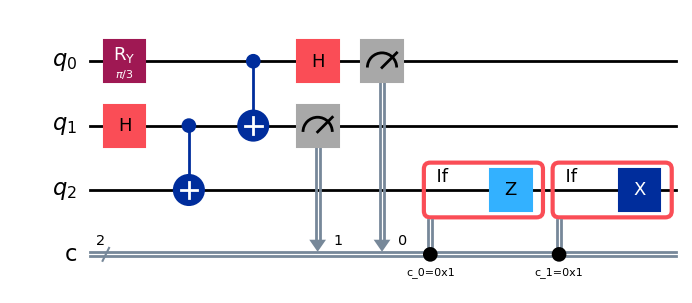

In [9]:
# DISEÑA TU SOLUCIÓN AQUÍ
# Crear el circuito con 3 qubits y 2 bits clásicos
qc = QuantumCircuit(3, 2)

# Paso 1: Crear el estado que queremos teleportar en q0
qc.ry(np.pi/3, 0)  # Estado a teleportar

# Paso 2: Crear el par de Bell entre Alice (q1) y Bob (q2)
qc.h(1)
qc.cx(1, 2)

# Paso 3: Alice aplica operaciones sobre q0 y q1
qc.cx(0, 1)
qc.h(0)

# Paso 4: Alice mide sus qubits
qc.measure(0, 0)
qc.measure(1, 1)

# Paso 5: Bob aplica correcciones según los resultados
# Usar with para aplicar las operaciones condicionales
with qc.if_test((0, 1)):
    qc.z(2)
with qc.if_test((1, 1)):
    qc.x(2)

qc.draw('mpl')

**NOTA:** Estas preguntas deben responderse con texto en los recuadros habilitados



___________________________________



**1.-** Si se había comentado que el Teorema de No Clonación impide copiar de forma exacta un estado desconocido, ¿por qué funciona el protocolo? ¿Qué ha pasado? ¿Estamos violando el Teorema de No Clonación?

NOTA: Para responder esta pregunta, es MUY recomendable que leas los recursos propuestos sobre el Teorema de No Clonación y entender sus hipótesis.


In [ ]:
### RESPUESTA 1:
### No violamos el teorema porque no estamos copiando el estado.
### Cuando Alice mide sus qubits, el estado original se destruye.
### Solo queda la información en el qubit de Bob después de las correcciones.
### El estado se transfiere de un lugar a otro, no se duplica.


**2.-** Corren los tiempos de 2721, y, para tu desgracia, te han nombrado jefe de comunicaciones de la nave espacial Discovery. La almirante te ha ordenado enviar un importantísimo mensaje que ha codificado en un qubit a la ETSII, de la que te encuentras actualmente a 5 años luz. Debido a la distancia, cualquier intento de comunicación clásica sería inútil. Sin embargo, fuiste una persona previsora, y, antes de salir, generaste varios pares de Bell, dejando uno de los qubits entrelazados en la ETSII y el otro en la nave espacial, en caso de que tuvieras que aplicar el protocolo de teletransportación cuántica.

¿Puedes cumplir las órdenes de la almirante? Es decir, ¿puedes aplicar el protocolo de teletransportación cuántica sin utilizar un canal clásico? En caso afirmativo, indica cómo en el recuadro de abajo y realiza una implementación en la casilla "IMPLEMENTACIÓN". En caso negativo, explica por qué no.

In [ ]:
### RESPUESTA 2:
### No, no es posible sin un canal clásico.
### El protocolo de teletransportación cuántica necesita obligatoriamente un canal clásico.
### para transmitir los 2 bits de información que resultan de las mediciones de Alice.
### Sin esta información clásica, Bob no sabe qué operaciones debe aplicar sobre el qubit.


In [11]:
### IMPLEMENTACIÓN
print("No se puede hacer teletransportación sin canal clásico")

No se puede hacer teletransportación sin canal clásico


# 2. Construcción de un estado GHZ de forma eficiente

## <i>Enunciado</i>

A la hora de diseñar un circuito cuantico no es solo importante el numero de puertas que tiene el circuito sino tambien su  [profundidad](https://quantum.cloud.ibm.com/docs/en/guides/construct-circuits#what-is-circuit-depth) ([¿se te ocurre por qué?](https://quantumcomputing.stackexchange.com/questions/18177/why-is-depth-complexity-relevant)).  

En este caso el reto consiste en crear un  [estado GHZ](https://en.wikipedia.org/wiki/Greenberger%E2%80%93Horne%E2%80%93Zeilinger_state) de **25 qubits**.  

Hay una forma fácil de hacerlo lanzando puertas **CNOT** a lo loco que conseguiria una profundidad de **25**, es decir el circuito tendría profundidad **O(n)**.  

El reto consiste en diseñar un circuito que también cree el estado GHZ, pero con una **profundidad de O(log n)**.  
En este caso, deberíais obtener una **profundidad de 6 (¡o menos! 😄)**.



In [13]:
num_qubits = 25
qc = QuantumCircuit(num_qubits)

### IMPLEMENTACIÓN
# Aplicar Hadamard al primer qubit
qc.h(0)

# Estrategia logarítmica: duplicar el entrelazamiento en cada capa
# Capa 1: entrelazar qubit 0 con qubit 1 (2^1 qubits entrelazados)
qc.cx(0, 1)

# Capa 2: los 2 qubits entrelazados enredan a 2 más (2^2 = 4 qubits)
qc.cx(0, 2)
qc.cx(1, 3)

# Capa 3: los 4 qubits entrelazados enredan a 4 más (2^3 = 8 qubits)
qc.cx(0, 4)
qc.cx(1, 5)
qc.cx(2, 6)
qc.cx(3, 7)

# Capa 4: los 8 qubits entrelazados enredan a 8 más (2^4 = 16 qubits)
qc.cx(0, 8)
qc.cx(1, 9)
qc.cx(2, 10)
qc.cx(3, 11)
qc.cx(4, 12)
qc.cx(5, 13)
qc.cx(6, 14)
qc.cx(7, 15)

# Capa 5: los 16 qubits entrelazados enredan a 9 más (llegamos a 25)
qc.cx(0, 16)
qc.cx(1, 17)
qc.cx(2, 18)
qc.cx(3, 19)
qc.cx(4, 20)
qc.cx(5, 21)
qc.cx(6, 22)
qc.cx(7, 23)
qc.cx(8, 24)

print('Depth: ', qc.depth())

estado_ghz = Statevector(qc)
estado_ghz.draw('latex')

Depth:  6


<IPython.core.display.Latex object>

# 3. Corrección de errores

## <i> Enunciado </i>

Como se ha visto a lo largo de las sesiones teóricas, los qubits son [muy frágiles](https://es.wikipedia.org/wiki/Decoherencia_cu%C3%A1ntica). Si no tuviéramos los problemas que genera el teorema de no clonación (¿te acuerdas? Se habló un poco de él en el ejercicio 2. Este puede ser un buen momento para revisar el contenido), la solución sería bien simple: copiamos muchas veces el estado que no queremos perder y aplicamos corrección de errores clásica.

El mundo no es tan bonito, así que tendremos que tener algo más de creatividad. Lo que haremos será, en lugar de guardar la información en un solo qubit, distribuirla **en varios**. El objetivo de esta breve práctica es implementar el **código de repetición de 3 qubits**, que protegerá de errores del tipo bit-flip. Esto es, transformaremos nuestros estados de la siguiente manera:

$$|\psi⟩ = \alpha|0⟩ + \beta|1⟩ \to \alpha|000⟩ + \beta|111⟩$$

Para esto, como pista, deberás utilizar dos qubits más además del que tenías al empezar, y aplicar algunas puertas CNOT entre ellos.

Una vez hayas conseguido hacer esa transformación, tendrás que aplicar un bit-flip manual a alguno de los qubits para simular un error, tras lo que deberás encontrar una forma de averiguar si se ha producido un error. Esto último debes hacerlo **sin medir los qubits** (¿por qué?), por lo que necesitarás un par de qubits extra más, llamados *ancilla*. Tras detectarlo, debes corregir el error.

Puedes echarle un vistazo [a estas diapositivas de la Universidad de Cambridge](https://www.cl.cam.ac.uk/teaching/1920/QuantComp/Quantum_Computing_Lecture_13.pdf) y a [esta guía de IBM Quantum](https://quantum.cloud.ibm.com/docs/es/tutorials/repetition-codes) donde se da una explicación teórica y una implementación en Qiskit de este problema junto a algunos añadidos. Lo importante es que entiendas que este método se divide en varias etapas, al igual que la detección y correción de errores clásicos.

Protocolo implementado


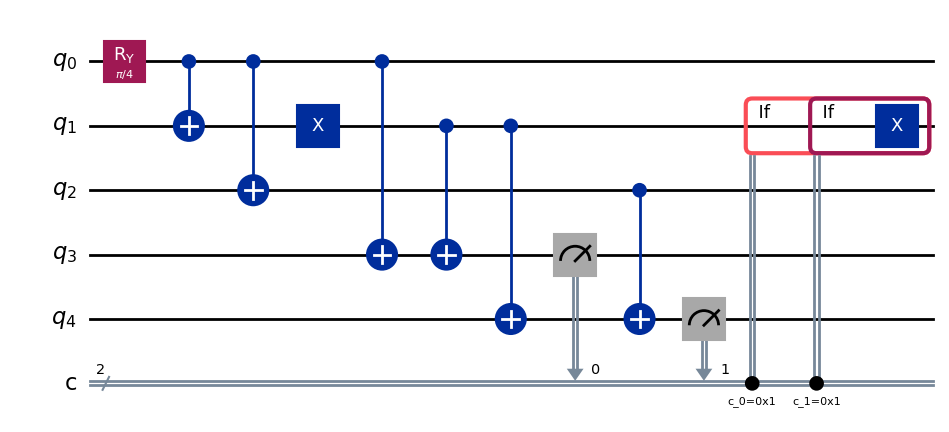

In [14]:
## IMPLEMENTA AQUÍ EL PROTOCOLO DE CORRECCIÓN DE ERRORES.

qc = QuantumCircuit(5, 2)

# Estado a proteger
qc.ry(np.pi/4, 0)

# Codificación: α|0⟩ + β|1⟩ → α|000⟩ + β|111⟩
qc.cx(0, 1)
qc.cx(0, 2)

# Simular error en qubit 1
qc.x(1)

# Detección con ancillas
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(1, 4)
qc.cx(2, 4)

# Medir ancillas
qc.measure(3, 0)
qc.measure(4, 1)

# Corrección: si ambas ancillas son 1, el error está en qubit 1
with qc.if_test((0, 1)):
    with qc.if_test((1, 1)):
        qc.x(1)

print("Protocolo implementado")
qc.draw('mpl')

Ahora comienzan algunas preguntas teóricas ;)

Puede que pienses que este código es muy malo, pues, ¿qué ocurre con otro tipo de errores, como los phase-flip? Quizá nuestro estado $|\psi⟩ = \alpha|0⟩ + \beta|1⟩$ se convierte en $|\psi⟩ = \alpha|0⟩ - \beta|1⟩$. ¡Y tienes toda la razón!

Pero podemos arreglarlo de una forma sencilla :). ¿Qué habría que cambiar del método anterior para que corrigiera errores de phase-flip?

**PISTA**: ¿Qué puerta modela los errores de bit-flip ($|0⟩ \to |1⟩$; $|1⟩ \to |1⟩$)? ¿Se te ocurre alguna otra puerta que modele, en este caso, errores de phase-flip?

In [ ]:
# ESCRIBE AQUÍ TU RESPUESTA
# Los bit-flip son causados por la puerta X.
# Los phase-flip son causados por la puerta Z.
# Para corregir phase-flip, aplicamos Hadamard antes y después
# del protocolo. Esto convierte errores Z en errores X que ya
# sabemos corregir.

Por último, supongamos que somos personas ambiciosas y queremos corregir **de forma simultánea** errores **de phase-flip y de bit-flip**. Investiga si existe alguna forma de hacerlo, y esboza en qué consiste ese método. ¿En qué se diferencia este método de los dos que hemos visto anteriormente? ¿Cuántos qubits utiliza en total? Compáralo con el número de qubits que tiene el nuevo superordenador cuántico que ha inaugurado IBM en País Vasco y saca tus propias conclusiones.

In [ ]:
# RESPONDE AQUÍ
# Sí, existe el código de Shor que usa 9 qubits para proteger 1 qubit lógico.
# Funciona combinando protección contra phase-flip (que necesita 3 qubits)
# y luego cada uno de esos se protege contra bit-flip (3*3=9 total).
# La diferencia es que los anteriores solo protegen un tipo de error,
# este protege ambos. Pero es muy costoso: 9 qubits físicos por cada
# qubit útil.
# El ordenador de IBM tiene unos 100 qubits, con código de Shor tendríamos
# solo unos 11 qubits lógicos utilizables. Por eso la corrección de errores
# cuántica necesita muchos recursos.

# 4. <i>Tomografía (Opcional) </i>

## <i>Enunciado</i>

A estas alturas debería resultar evidente que realizar una medición únicamente en la base $\{ |0\rangle, |1\rangle \}$ no nos permite conocer con exactitud el estado de un qubit. Como mucho, obtenemos su proyección en dicha base. Esto implica que perderemos información esencial, en particular la fase del qubit.

Para resolver este problema, en este ejercicio llevaremos a cabo un proceso llamado tomografía de estados. En lugar de limitarnos a medir en la base computacional $\{ |0\rangle, |1\rangle \}$, también realizaremos mediciones en las bases $\{ |+\rangle, | - \rangle \}$ y $\{ |+y\rangle, | -y\rangle \}$.

De esta manera podremos reconstruir el estado completo de un qubit a partir de sus proyecciones en diferentes bases. Para comenzar, se te proporcionará un estado aleatorio mediante el comando `random_state`

Recuerda que [todo estado de un qubit se puede escribir como](https://talentq-es.github.io/TalentQ-CICC/docs/Part_02_Cubits/Chapter_01_02_Circuitos_1_cubit/Section_021_Cubits_myst.html#esfera-de-bloch):


$$
|\psi\rangle = \begin{pmatrix}
 \cos(\theta/2)\\
 e^{i\phi}\sin(\theta/2)
\end{pmatrix}.
$$
Es decir, solo tienes que encontrar $\theta$ y $\phi$.

---
**Recursos útiles:**

- https://talentq-es.github.io/TalentQ-CICC/docs/Part_01_Formalismo/Chapter_02_01_Fundamentos_MC_myst.html#medidas-y-valores-esperados


- https://quantum.cloud.ibm.com/docs/en/guides/primitives#estimator


In [19]:
psi = random_statevector(2)
a0, a1 = psi.data
print(f"|ψ⟩ = {np.round(a0.real,3)}{'+' if a0.imag>=0 else ''}{np.round(a0.imag,3)}i|0⟩ + {np.round(a1.real,3)}{'+' if a1.imag>=0 else ''}{np.round(a1.imag,3)}i|1⟩")
init_gate = Initialize(psi)
init_gate.label = "Estado Aleatorio"

qc = QuantumCircuit(1)
qc.append(init_gate, [0])

### IMPLEMENTACIÓN

backend = AerSimulator()
shots = 10000

# Medir en base Z
qc_z = qc.copy()
qc_z.measure_all()

# Medir en base X
qc_x = qc.copy()
qc_x.h(0)
qc_x.measure_all()

# Medir en base Y
qc_y = qc.copy()
qc_y.sdg(0)
qc_y.h(0)
qc_y.measure_all()

# Ejecutar
counts_z = backend.run(qc_z, shots=shots).result().get_counts()
counts_x = backend.run(qc_x, shots=shots).result().get_counts()
counts_y = backend.run(qc_y, shots=shots).result().get_counts()

# Calcular valores esperados
exp_z = (counts_z.get('0', 0) - counts_z.get('1', 0)) / shots
exp_x = (counts_x.get('0', 0) - counts_x.get('1', 0)) / shots
exp_y = (counts_y.get('0', 0) - counts_y.get('1', 0)) / shots

# Escribe tu respuesta aquí
phi = np.arctan2(exp_y, exp_x)
theta = np.arccos(np.clip(exp_z, -1, 1))

|ψ⟩ = 0.591+0.25i|0⟩ + -0.684-0.348i|1⟩


## <i>Corrector</i>

In [20]:
psi_est = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])
fidelity = abs(np.vdot(psi_est, psi))**2
if fidelity > 0.999:
    print("✅ Respuesta correcta")
else:
    print("❌ Respuesta incorrecta")

✅ Respuesta correcta
